# MP05: Gillespie Direct SSA Engine Implementation
**Complex Systems / App Physics 195**


In [2]:
# using Pkg; Pkg.add(["Distributions", "Plots"])
using Random, Statistics, Printf
using Distributions 
using Plots

default(linewidth = 2, framestyle = :box, gridalpha = 0.25, legendfontsize = 8,
        titlefontsize = 10, guidefontsize = 9)
mkpath("figures")     

"figures"

## KR1: Core Gillespie Direct Algorithm Implementation

### 1. Algorithm description & implementation

State $\mathbf{x}$, channels $\mu=1..M$ with propensities $a_\mu(\mathbf{x})$ and change vectors $\boldsymbol\nu_\mu$. Each step:

1. evaluate every $a_\mu(\mathbf{x})$ and the total $a_0=\sum_\mu a_\mu$;
2. sample the waiting time $\tau=-\ln(r_1)/a_0\sim\text{Exp}(a_0)$;
3. sample the channel $\mu$ by cumulative lookup: the smallest $\mu$ with $\sum_{\nu\le\mu}a_\nu > r_2a_0$, so $P(\mu)=a_\mu/a_0$;
4. advance $t\leftarrow t+\tau$, $\mathbf{x}\leftarrow\mathbf{x}+\boldsymbol\nu_\mu$.

In [3]:
# ----------------------------------------------------------------------------
# Model container: stoichiometry + in-place propensity function + parameters
# ----------------------------------------------------------------------------
struct ReactionNetwork{F}
    stoich::Matrix{Int}          # n_species x n_reactions; column μ is the change vector ν_μ
    propensity!::F               # propensity!(a, x, p) fills a[μ] = a_μ(x) in place
    p::Vector{Float64}           # parameters handed to the propensity function
    species::Vector{String}
    reactions::Vector{String}
end

function ReactionNetwork(stoich::AbstractMatrix{<:Integer}, propensity!, p;
                         species   = ["X$i" for i in 1:size(stoich, 1)],
                         reactions = ["R$j" for j in 1:size(stoich, 2)])
    return ReactionNetwork(Matrix{Int}(stoich), propensity!, Float64.(collect(p)),
                           String.(species), String.(reactions))
end

# -----------------------------------------------------
# Returns the smallest μ with  Σ_{ν≤μ} a_ν > r2 · a0.
# -----------------------------------------------------
@inline function sample_reaction(a::AbstractVector{Float64}, a0::Float64, r2::Float64)
    target = r2 * a0                   # uniform point on [0, a0)
    cum = 0.0
    @inbounds for μ in eachindex(a)
        cum += a[μ]                    # running cumulative propensity
        target < cum && return μ       # strict '<': a channel with a_μ = 0 can never be chosen
    end
    # Floating-point round-off fallback: last channel with positive propensity
    @inbounds for μ in length(a):-1:1
        a[μ] > 0 && return μ
    end
    error("sample_reaction called with all-zero propensities")
end

# -------------------------------------------------------------------------------------------
# Gillespie Direct Method
#   net        : ReactionNetwork
#   x0         : initial copy numbers
#   tmax       : end time (may be Inf: run until absorption or max_events)
#   record     : true  -> store the full trajectory (times, states)
#                false -> store only the final state (fast, used for large ensembles)
# Returns (times, states, x_final, t_final, n_events); `states` is n_species x n_points.
# -------------------------------------------------------------------------------------------
function gillespie_direct(net::ReactionNetwork, x0::AbstractVector{<:Integer}, tmax::Real;
                          rng::AbstractRNG = Random.default_rng(),
                          record::Bool = true,
                          max_events::Int = typemax(Int))
    S = net.stoich
    nspecies, nreact = size(S)
    x = Vector{Int}(x0)                # working copy of the state
    a = zeros(Float64, nreact)         # propensities a_μ(x)
    t = 0.0
    nev = 0
    hit_tmax = false
    absorbed = false

    times  = Float64[]
    states = Vector{Vector{Int}}()
    if record
        push!(times, 0.0); push!(states, copy(x))
    end

    while nev < max_events
        # (1) propensities a_μ(x) and their sum a0
        net.propensity!(a, x, net.p)
        a0 = sum(a)

        # (2) ABSORBING STATE: a0 = 0 means no reaction can ever fire again ==> stop
        if !(a0 > 0)
            absorbed = true
            break
        end

        # (3) time to next event, τ ~ Exp(a0).  1 - U[0,1) lies in (0,1], so log() is finite.
        τ = -log(1.0 - rand(rng)) / a0

        # (4) TIME-BOUNDARY OVERSHOOT: if the next event falls beyond tmax, discard it.
        #     (valid because the exponential is memoryless: the state is frozen on [t, tmax])
        if t + τ > tmax
            hit_tmax = true
            break
        end
        t += τ

        # (5) which reaction fires: μ chosen with probability a_μ / a0
        μ = sample_reaction(a, a0, rand(rng))

        # (6) update the state with ν_μ
        @inbounds for i in 1:nspecies
            x[i] += S[i, μ]
        end
        nev += 1
        if record
            push!(times, t); push!(states, copy(x))
        end
    end

    # If the run ended by absorption or at tmax (finite), report t_final = tmax
    t_final = (hit_tmax || (absorbed && isfinite(tmax))) ? Float64(tmax) : t
    if record && t_final > times[end]
        push!(times, t_final); push!(states, copy(x))
    end
    M = record ? reduce(hcat, states) : zeros(Int, nspecies, 0)
    return (times = times, states = M, x_final = x, t_final = t_final, n_events = nev)
end

# Sample many recorded runs on a common time grid (paths are piecewise constant)
function ensemble_on_grid(runs, grid, s::Int)
    out = Matrix{Int}(undef, length(runs), length(grid))
    for (r, run) in enumerate(runs), (m, g) in enumerate(grid)
        out[r, m] = run.states[s, searchsortedlast(run.times, g)]
    end
    return out
end

ensemble_on_grid (generic function with 1 method)

### 2. Implementation verification

**Absorbing states ($a_0=0$).** If every propensity is zero the waiting time $\tau=-\ln r/a_0$ would be infinite, so the solver tests `a0 > 0` before sampling and exits the loop. The state is then frozen. With finite `tmax` the plateau is extended to `tmax`; with `tmax = Inf` the run ends at the last event. This is how an SIR trajectory terminates at $I=0$ (both $a_1\propto SI$ and $a_2\propto I$ vanish). The `!(a0 > 0)` form also stops on `NaN`.

**Time-boundary overshoot ($t+\tau>t_{\max}$).** The candidate event is discarded and the state is held at its current value up to `tmax`. This is exact, not an approximation: the exponential waiting time is memoryless, so no event occurred in $(t,t_{\max}]$ with the correct probability, and the state at `tmax` is the state after the last event before it. Discarding (rather than applying) the event avoids a bias toward states that lie beyond the observation window.

**Primitive tests.** (a) channel frequencies for propensities `[1,3,0,6]` against `[0.1,0.3,0,0.6]` (χ² test; the zero-rate channel must never fire); (b) inter-event times of a single constant-rate reaction against Exp(5) (mean, std, Kolmogorov-Smirnov).

In [ ]:
let rng = Xoshiro(1)
    # ---- (a) channel selection ----
    a  = [1.0, 3.0, 0.0, 6.0];  a0 = sum(a);  n = 10^6
    counts = zeros(Int, length(a))
    for _ in 1:n
        counts[sample_reaction(a, a0, rand(rng))] += 1
    end
    probs = a ./ a0
    nz = findall(>(0), probs)
    χ2 = sum((counts[nz] .- n .* probs[nz]).^2 ./ (n .* probs[nz]))
    println("Channel frequencies  empirical: ", round.(counts ./ n, digits = 4), "   exact: ", probs)
    @printf("  zero-propensity channel picked %d times;  χ² = %.2f, p = %.3f\n", counts[3], χ2, ccdf(Chisq(length(nz) - 1), χ2))

    # ---- (b) waiting times through the full solver ----
    rate = 5.0
    poisson_proc = ReactionNetwork(fill(1, 1, 1), (a, x, p) -> (a[1] = p[1]; nothing), [rate])
    r  = gillespie_direct(poisson_proc, [0], Inf; rng = rng, max_events = 200_000)
    τs = diff(r.times)
    @printf("Waiting times: mean = %.4f (exact %.4f), std = %.4f (exact %.4f)\n", mean(τs), 1 / rate, std(τs), 1 / rate)
    sorted = sort(τs); m = length(sorted); E = Exponential(1 / rate)
    D = maximum(max(abs(i / m - cdf(E, sorted[i])), abs((i - 1) / m - cdf(E, sorted[i]))) for i in 1:m)
    @printf("  KS distance = %.5f  (5%% critical value %.5f)\n", D, 1.36 / sqrt(m))

    # ---- (c) absorbing state and overshoot ----
    dying = ReactionNetwork(fill(-1, 1, 1), (a, x, p) -> (a[1] = p[1] * x[1]; nothing), [1.0])
    r1 = gillespie_direct(dying, [20], Inf; rng = rng)
    @printf("Pure death, tmax = Inf : ended at X = %d after %d events (absorbed)\n", r1.x_final[1], r1.n_events)
    r2 = gillespie_direct(dying, [20], 0.5; rng = rng)
    @printf("Pure death, tmax = 0.5 : t_final = %.2f, last recorded time = %.2f ≤ tmax\n", r2.t_final, r2.times[end])
end

Channel frequencies  empirical: [0.1004, 0.2992, 0.0, 0.6004]   exact: [0.1, 0.3, 0.0, 0.6]
  zero-propensity channel picked 0 times;  χ² = 3.66, p = 0.160
Waiting times: mean = 0.2001 (exact 0.2000), std = 0.2000 (exact 0.2000)
  KS distance = 0.00151  (5% critical value 0.00304)
Pure death, tmax = Inf : ended at X = 0 after 20 events (absorbed)
Pure death, tmax = 0.5 : t_final = 0.50, last recorded time = 0.50 ≤ tmax


## KR2: Sanity check & model validation (constitutive birth-death)

### 1. Model formulation

$$\varnothing\xrightarrow{k_1}X\ \ (a_1=k_1),\qquad X\xrightarrow{k_2}\varnothing\ \ (a_2=k_2X)$$

Parameters: $k_1=50.0$, $k_2=1.0$, $x_0=[0]$, $t_{\max}=10.0$, so $\lambda=k_1/k_2=50$. The exact solution from $x_0=0$ is Poisson with mean $\lambda(1-e^{-k_2t})$ at every $t$; at $t_{\max}=10$ the transient correction is $\lambda e^{-10}\approx 2\times10^{-3}$, which is negligible.

In [18]:
k1, k2 = 50.0, 1.0
λ = k1 / k2

bd_prop!(a, x, p) = (a[1] = p[1]; a[2] = p[2] * x[1]; nothing)     # a1 = k1, a2 = k2·X
bd = ReactionNetwork([1 -1], bd_prop!, [k1, k2]; species = ["X"], reactions = ["∅ → X (birth)", "X → ∅ (death)"])

ntraj = 1000
tmax_bd = 10.0
tgrid_bd = 0.0:0.1:tmax_bd
rng_bd = Xoshiro(20240601)

bd_runs = [gillespie_direct(bd, [0], tmax_bd; rng = rng_bd) for _ in 1:ntraj]
Xbd     = ensemble_on_grid(bd_runs, tgrid_bd, 1)        # ntraj x length(tgrid)
finals  = Xbd[:, end]                                   # X(t_max) for each run

1000-element Vector{Int64}:
 52
 43
 55
 53
 47
 50
 43
 44
 32
 38
  ⋮
 45
 55
 48
 41
 56
 57
 56
 49
 51

### 2. Results & validation plot
Normalized histogram of $X(t_{\max})$ over 1,000 runs, overlaid with $P(X=k)=\lambda^ke^{-\lambda}/k!$, $\lambda=50$; and the transient mean and variance against theory.

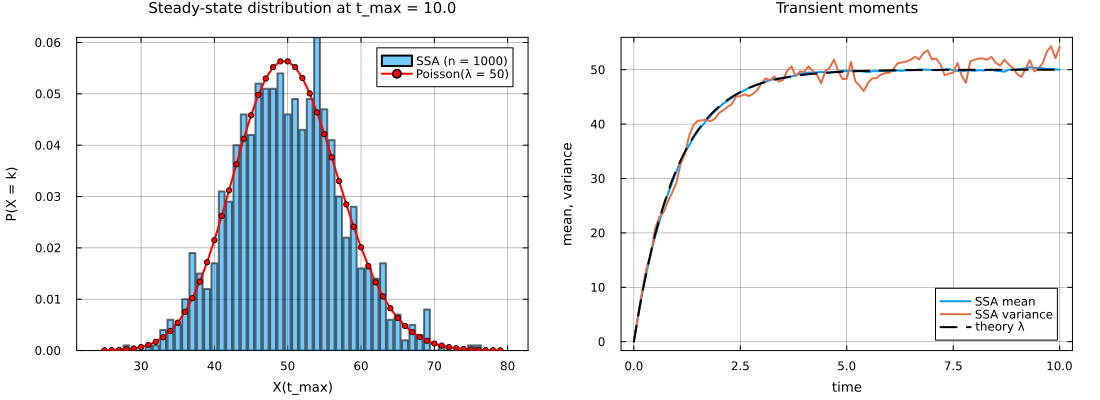

In [ ]:
ks      = max(0, minimum(finals) - 3):(maximum(finals) + 3)
emp_pmf = [count(==(m), finals) / ntraj for m in ks]

p1 = bar(ks, emp_pmf; alpha = 0.55, label = "SSA (n = $ntraj)", xlabel = "X(t_max)", ylabel = "P(X = k)", title = "Steady-state distribution at t_max = $(tmax_bd)")
plot!(p1, ks, pdf.(Poisson(λ), ks); marker = :circle, markersize = 3, c = :red, label = "Poisson(λ = $(Int(λ)))")

tt = collect(tgrid_bd)
p2 = plot(tt, vec(mean(Xbd; dims = 1)); label = "SSA mean", xlabel = "time", ylabel = "mean, variance", title = "Transient moments")
plot!(p2, tt, vec(var(Xbd; dims = 1)); label = "SSA variance")
plot!(p2, tt, λ .* (1 .- exp.(-k2 .* tt)); ls = :dash, c = :black, label = "theory λ(1−e^{−k₂t}) (mean = var)", legend = :bottomright)

fig_kr2 = plot(p1, p2; layout = (1, 2), size = (1100, 400), margin = 5Plots.mm)
savefig(fig_kr2, "figures/kr2_birth_death.png")
fig_kr2

### 3. Statistical comparison
The table below is printed in Markdown, ready to paste into the report. Because there are only 1,000 samples, a non-zero relative error is expected from sampling noise alone: $\text{SE}(\bar X)=\sqrt{\lambda/n}$ and $\text{SE}(s^2)\approx\sqrt{(\lambda+2\lambda^2)/n}$. These are printed next to the observed errors, along with a χ² goodness-of-fit test (tail bins pooled to expected count ≥ 5) and a replication study.

In [ ]:
relerr(e, t) = 100 * abs(e - t) / t

emp_mean = mean(finals);  emp_var = var(finals)
se_mean  = sqrt(λ / ntraj)
se_var   = sqrt((λ + 2λ^2) / ntraj)

println("| Metric | Empirical (SSA Ensemble) | Theoretical Poisson (λ = $(Int(λ))) | Relative Error (%) |")
# println("|---|---|---|---|")
@printf("| Mean ⟨X⟩ | %.3f | %.2f | %.3f |\n", emp_mean, λ, relerr(emp_mean, λ))
@printf("| Variance σ²_X | %.3f | %.2f | %.3f |\n", emp_var, λ, relerr(emp_var, λ))
@printf("\nExpected sampling noise (1 s.e.): mean %.3f%%,  variance %.3f%%\n", 100 * se_mean / λ, 100 * se_var / λ)
@printf("Observed deviation in s.e. units : mean %.2f,  variance %.2f\n", (emp_mean - λ) / se_mean, (emp_var - λ) / se_var)
@printf("Fano factor = %.3f (Poisson ⇒ 1)\n", emp_var / emp_mean)

| Metric | Empirical (SSA Ensemble) | Theoretical Poisson (λ = 50) | Relative Error (%) |
| Mean ⟨X⟩ | 49.993 | 50.00 | 0.014 |
| Variance σ²_X | 54.275 | 50.00 | 8.550 |

Expected sampling noise (1 s.e.): mean 0.447%,  variance 4.494%
Observed deviation in s.e. units : mean -0.03,  variance 1.90
Fano factor = 1.086 (Poisson ⇒ 1)


In [8]:
# Pearson χ² goodness-of-fit against Poisson(λ); tail bins pooled so every expected count >= minexp
function poisson_gof(samples, λ; minexp = 5.0)
    n = length(samples); P = Poisson(λ)
    kmin = first(m for m in 0:1000    if n * cdf(P, m)       >= minexp)
    kmax = first(m for m in 1000:-1:0 if n * ccdf(P, m - 1)  >= minexp)
    obs  = Float64[count(<=(kmin), samples)]
    expd = Float64[n * cdf(P, kmin)]
    for m in (kmin + 1):(kmax - 1)
        push!(obs, count(==(m), samples)); push!(expd, n * pdf(P, m))
    end
    push!(obs, count(>=(kmax), samples)); push!(expd, n * ccdf(P, kmax - 1))
    χ2 = sum((obs .- expd) .^ 2 ./ expd); df = length(obs) - 1
    return (χ2 = χ2, df = df, p = ccdf(Chisq(df), χ2))
end

gof = poisson_gof(finals, λ)
@printf("χ² GOF at t_max: χ² = %.2f, df = %d, p = %.3f → %s at the 5%% level\n",
        gof.χ2, gof.df, gof.p, gof.p > 0.05 ? "cannot reject Poisson(λ)" : "REJECTED")

# Replication study: a correct sampler gives ~uniform p-values, so ≈5% of replicates reject at 5%
reps = 50
rng_rep = Xoshiro(777)
pvals = [poisson_gof([gillespie_direct(bd, [0], tmax_bd; rng = rng_rep, record = false).x_final[1]
                      for _ in 1:ntraj], λ).p for _ in 1:reps]
@printf("Replicates: %d × %d runs.  Fraction rejecting at 5%%: %.2f (≈ 0.05 expected);  mean p = %.3f (uniform ⇒ 0.5)\n",
        reps, ntraj, mean(pvals .< 0.05), mean(pvals))

χ² GOF at t_max: χ² = 39.02, df = 36, p = 0.336 → cannot reject Poisson(λ) at the 5% level
Replicates: 50 × 1000 runs.  Fraction rejecting at 5%: 0.06 (≈ 0.05 expected);  mean p = 0.556 (uniform ⇒ 0.5)


**Conclusion (KR2).** If the χ² p-value exceeds 0.05, the observed mean and variance lie within about 2 standard errors of $\lambda=50$ (Fano ≈ 1), and the replicate rejection rate is near 5 %, the distribution of $X(t_{\max})$ is statistically indistinguishable from Poisson(50). This validates both the exponential waiting-time sampler and the channel-selection rule.

## KR3: Stochastic SIR epidemic trajectory dynamics

### 1. Model configuration

1. Infection: $S+I\xrightarrow{\beta/N}2I$, $\boldsymbol\nu_1=[-1,1,0]^T$, propensity $a_1=\beta SI/N$
2. Recovery: $I\xrightarrow{\gamma}R$, $\boldsymbol\nu_2=[0,-1,1]^T$, propensity $a_2=\gamma I$

Parameters: $N=500$, $I_0=3$, $S_0=497$, $R_0=0$, $\beta=0.3$, $\gamma=0.1$ ($\mathcal{R}_0=3.0$), $t_{\max}=100$. Mean-field ODE: $\dot S=-\beta SI/N,\ \dot I=\beta SI/N-\gamma I,\ \dot R=\gamma I$ (hand-written RK4). Ensemble: 1,000 SSA runs.

In [9]:
N      = 500
I0     = 3
S0     = N - I0
β      = 0.3
γ      = 0.1
R0_sir = β / γ
tmax_sir = 100.0

sir_prop!(a, x, p) = (a[1] = p[1] * x[1] * x[2] / p[3];     # infection  a1 = β S I / N
                      a[2] = p[2] * x[2];                   # recovery   a2 = γ I
                      nothing)

sir = ReactionNetwork([-1  0;
                        1 -1;
                        0  1], sir_prop!, [β, γ, N];
                      species = ["S", "I", "R"], reactions = ["infection", "recovery"])

# ---- deterministic mean-field (RK4) ----
function sir_ode(β, γ, N, S0, I0, tmax; dt = 0.01)
    f(u) = [-β * u[1] * u[2] / N, β * u[1] * u[2] / N - γ * u[2], γ * u[2]]
    ts = 0.0:dt:tmax
    U  = zeros(3, length(ts));  U[:, 1] = [S0, I0, 0]
    for n in 1:(length(ts) - 1)
        u  = U[:, n]
        k1 = f(u); k2 = f(u .+ dt / 2 .* k1); k3 = f(u .+ dt / 2 .* k2); k4 = f(u .+ dt .* k3)
        U[:, n + 1] = u .+ dt / 6 .* (k1 .+ 2 .* k2 .+ 2 .* k3 .+ k4)
    end
    return collect(ts), U
end
dt_ode = 0.01
ts_ode, U_ode = sir_ode(β, γ, N, S0, I0, tmax_sir; dt = dt_ode)

# ---- stochastic ensemble ----
nens     = 1000
rng_sir  = Xoshiro(42)
sir_runs = [gillespie_direct(sir, [S0, I0, 0], tmax_sir; rng = rng_sir) for _ in 1:nens]

grid_sir = 0.0:0.25:tmax_sir
I_ens    = ensemble_on_grid(sir_runs, grid_sir, 2)
I_mean   = vec(mean(I_ens; dims = 1))

# Outbreak classification (same 10 % rule): total infected = N - S_final
major_frac   = 0.10
total_inf    = [N - r.x_final[1] for r in sir_runs]          # R_final + I_final
is_major     = total_inf .>= major_frac * N
peak_I       = [maximum(r.states[2, :]) for r in sir_runs]
peak_time    = [r.times[argmax(r.states[2, :])] for r in sir_runs]

1000-element Vector{Float64}:
 23.277556357659385
 44.61609039029781
 25.41215899891663
 25.25752534591704
 28.695371532934303
 41.46798115907321
 40.55407960046904
 21.30604077307366
 32.53621883881288
 27.02936820068442
  ⋮
 34.72829474997772
 32.20784163843674
 27.71773394737218
 52.296055990926455
 23.367988692351695
 26.780095381520503
 34.305930693817515
 31.559597798695435
 32.67092618698973

### 2. Trajectory visualizations
Twenty individual realizations of $I(t)$ (fade-outs in grey), the ensemble average over 1,000 runs, and the mean-field ODE. Panels B–D support the analysis questions: time-aligned major outbreaks, the final-size distribution, and the distribution of peak times.

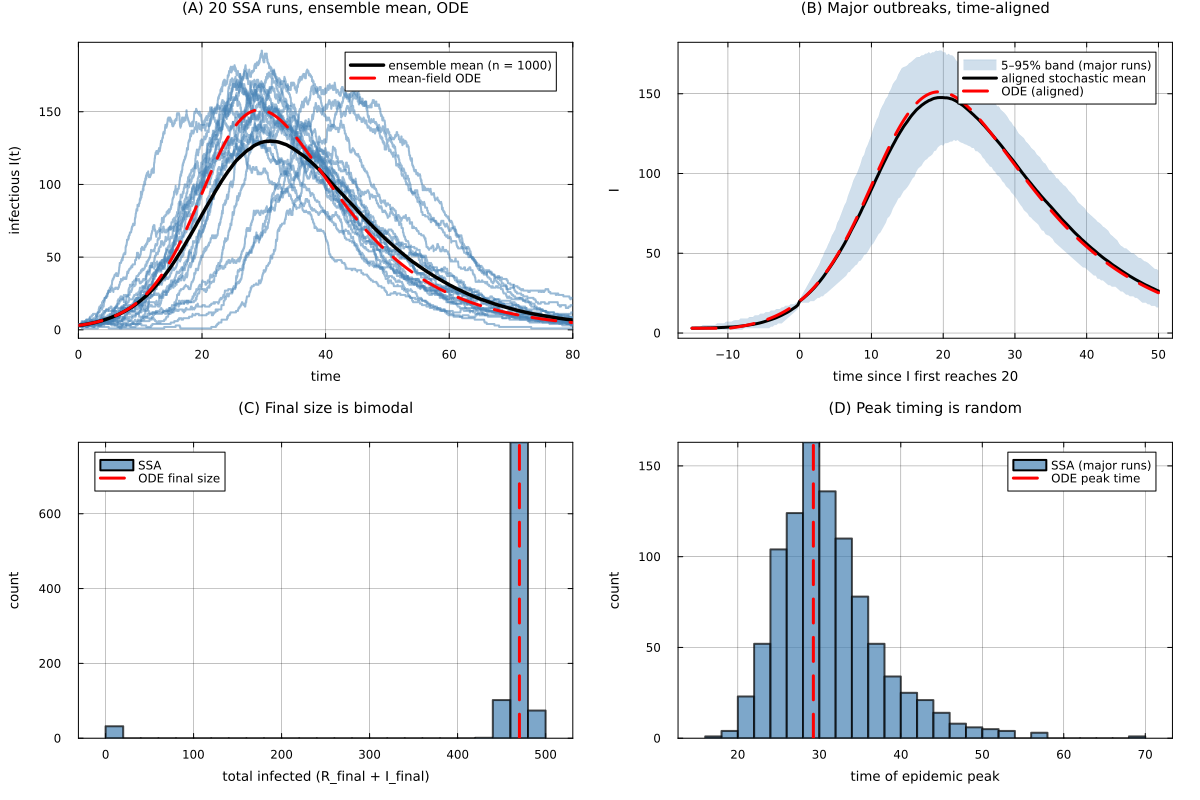

In [10]:
# ---- (A) 20 single trajectories + ensemble mean + ODE ----------------------
pA = plot(; xlabel = "time", ylabel = "infectious I(t)", xlims = (0, 80),
          title = "(A) 20 SSA runs, ensemble mean, ODE")
for (n, r) in enumerate(sir_runs[1:20])
    plot!(pA, r.times, r.states[2, :]; linetype = :steppost, alpha = 0.55,
          c = is_major[n] ? :steelblue : :gray, label = false)
end
plot!(pA, collect(grid_sir), I_mean; c = :black, lw = 3.5, label = "ensemble mean (n = $nens)")
plot!(pA, ts_ode, U_ode[2, :]; c = :red, ls = :dash, lw = 3, label = "mean-field ODE")

# ---- (B) major outbreaks aligned on first passage of I = thr ---------------------
thr = 20
function aligned_curves(runs, idxs, thr, τgrid)
    rows = Vector{Vector{Float64}}()
    for i in idxs
        r  = runs[i]
        ia = findfirst(>=(thr), view(r.states, 2, :))
        ia === nothing && continue
        ta = r.times[ia]
        push!(rows, [r.states[2, searchsortedlast(r.times, max(ta + τ, 0.0))] for τ in τgrid])
    end
    return reduce(hcat, rows)'
end
τgrid  = collect(-15.0:0.25:50.0)
A      = aligned_curves(sir_runs, findall(is_major), thr, τgrid)
A_mean = vec(mean(A; dims = 1))
A_lo   = [quantile(A[:, m], 0.05) for m in 1:size(A, 2)]
A_hi   = [quantile(A[:, m], 0.95) for m in 1:size(A, 2)]
ode_ta = ts_ode[findfirst(>=(thr), U_ode[2, :])]
ode_al = [U_ode[2, clamp(round(Int, (ode_ta + τ) / dt_ode) + 1, 1, length(ts_ode))] for τ in τgrid]

pB = plot(τgrid, A_hi; fillrange = A_lo, fillalpha = 0.25, c = :steelblue, lw = 0,
          label = "5–95% band (major runs)", xlabel = "time since I first reaches $thr",
          ylabel = "I", title = "(B) Major outbreaks, time-aligned")
plot!(pB, τgrid, A_mean; c = :black, lw = 3, label = "aligned stochastic mean")
plot!(pB, τgrid, ode_al; c = :red, ls = :dash, lw = 3, label = "ODE (aligned)")

# ---- (C) final size ---------------------------------------------------------------------
pC = histogram(total_inf; bins = 0:20:N, c = :steelblue, alpha = 0.7, label = "SSA",
               xlabel = "total infected (R_final + I_final)", ylabel = "count",
               title = "(C) Final size is bimodal")
vline!(pC, [N - U_ode[1, end]]; c = :red, ls = :dash, lw = 3, label = "ODE final size")

# ---- (D) peak timing ---------------------------------------------------------------------
pD = histogram(peak_time[is_major]; bins = 25, c = :steelblue, alpha = 0.7, label = "SSA (major runs)",
               xlabel = "time of epidemic peak", ylabel = "count", title = "(D) Peak timing is random")
vline!(pD, [ts_ode[argmax(U_ode[2, :])]]; c = :red, ls = :dash, lw = 3, label = "ODE peak time")

fig_kr3 = plot(pA, pB, pC, pD; layout = (2, 2), size = (1200, 800), margin = 5Plots.mm)
savefig(fig_kr3, "figures/kr3_sir.png")
fig_kr3

In [11]:
mj = findall(is_major)
ode_peak = maximum(U_ode[2, :]);  ode_pt = ts_ode[argmax(U_ode[2, :])];  ode_final = N - U_ode[1, end]

println("── SIR summary (N = $N, ℛ₀ = $R0_sir, I(0) = $I0, $nens runs) ──")
@printf("Early fade-out fraction: %.3f   (branching theory (1/ℛ₀)^I₀ = %.3f)\n",
        1 - length(mj) / nens, (1 / R0_sir)^I0)
@printf("\n%-36s %10s %10s\n", "", "SSA", "ODE")
@printf("%-36s %10.1f %10.1f\n", "peak I, mean over major runs",    mean(peak_I[mj]), ode_peak)
@printf("%-36s %10.1f %10s\n",   "peak I, std over major runs",     std(peak_I[mj]), "—")
@printf("%-36s %10.1f %10.1f\n", "peak of the ensemble-mean curve", maximum(I_mean), ode_peak)
@printf("%-36s %10.1f %10.1f\n", "peak time, mean (major runs)",    mean(peak_time[mj]), ode_pt)
@printf("%-36s %10.1f %10s\n",   "peak time, std (major runs)",     std(peak_time[mj]), "—")
@printf("%-36s %10.1f %10.1f\n", "final size, mean (major runs)",   mean(total_inf[mj]), ode_final)
@printf("%-36s %10.1f %10.1f\n", "final size, mean (all runs)",     mean(total_inf), ode_final)
fwhm_ens = let m = maximum(I_mean), idx = findall(>=(maximum(I_mean) / 2), I_mean)
    (idx[end] - idx[1]) * step(grid_sir)
end
fwhm_ode = let idx = findall(>=(ode_peak / 2), U_ode[2, :])
    (idx[end] - idx[1]) * dt_ode
end
@printf("\nFWHM of the ensemble-mean epidemic curve: %.1f   vs   ODE: %.1f\n", fwhm_ens, fwhm_ode)

── SIR summary (N = 500, ℛ₀ = 2.9999999999999996, I(0) = 3, 1000 runs) ──
Early fade-out fraction: 0.032   (branching theory (1/ℛ₀)^I₀ = 0.037)

                                            SSA        ODE
peak I, mean over major runs              158.9      151.2
peak I, std over major runs                15.8          —
peak of the ensemble-mean curve           129.8      151.2
peak time, mean (major runs)               31.2       29.3
peak time, std (major runs)                 6.2          —
final size, mean (major runs)             469.3      470.2
final size, mean (all runs)               454.5      470.2

FWHM of the ensemble-mean epidemic curve: 30.8   vs   ODE: 26.9


### 3. Analysis questions

**1. Smearing of the epidemic peak.** The average of many runs is lower and wider than any single outbreak for three connected reasons.
- *Random start-up delay.* While $I$ is of order $I_0=3$, infections and recoveries are a few discrete random events, so the time to reach an appreciable prevalence varies between runs. The epidemic then grows as $e^{(\beta-\gamma)t}$, which amplifies this early randomness into a spread in peak times (panel D). Each run has a sharp peak of height ≈ the major-run mean, but at different times. Averaging across these time-shifted peaks gives a lower and broader mean curve. Aligning major outbreaks on a common prevalence (panel B) removes most of this effect and the stochastic mean then follows the ODE shape much more closely.
- *Mixture with fade-outs.* A fraction of runs go extinct early and contribute $I\approx0$ at all later times. This pulls the average down by a factor of roughly $(1-P_{\text{fade}})$ (see KR4).

The printed table shows both effects: the peak of the ensemble-mean curve is below the mean single-run peak, and its FWHM is larger than the ODE's.

**2. Absorbing boundary.** Both propensities contain a factor of $I$ ($a_1=\beta SI/N$, $a_2=\gamma I$), so at $I=0$ we get $a_0=0$ and no reaction can fire again, since infection needs an infectious individual and nothing reintroduces one. The solver detects $a_0=0$ and stops, so extinction is **final** and is reached in finite time at the moment the last infectious individual recovers. In contrast the ODE has $\dot I=I(\beta S/N-\gamma)$, so $I(t)=I_0\exp\!\big(\int(\beta S/N-\gamma)\,dt\big)>0$ for all finite $t$. $I$ decays exponentially toward 0 but never reaches it, and the ODE keeps an arbitrarily small residual infectious "density" indefinitely. Also, for $\mathcal{R}_0>1$ and $I_0>0$ the ODE cannot extinguish before the epidemic takes off, whereas the SSA can reach the absorbing boundary at small $I$ with non-zero probability.

## KR4: Early fade-out & stochastic extinction analysis

### 1. Empirical vs. theoretical extinction sweep

Sweep $I_0\in\{1,\dots,10\}$ with 1,000 runs per $I_0$ under $\mathcal{R}_0=1.5$ ($\beta=0.15$, $\gamma=0.1$, $N=500$). An **early fade-out** is a run in which $I(t)\to0$ before the total number infected, $R_{\text{final}}+I_{\text{final}}=N-S_{\text{final}}$, exceeds $10\%$ of $N$ (i.e. 50 individuals). Each run is simulated to absorption ($t_{\max}=\infty$) with `record = false`, then classified from the final state.

**Theory.** For small $I/N$, $I(t)$ is a linear birth-death branching process (birth rate $\beta$, death rate $\gamma$ per individual). The extinction probability from one case is $\gamma/\beta=1/\mathcal{R}_0$, so from $I_0$ independent lineages $P(\text{extinction})=(1/\mathcal{R}_0)^{I_0}$. As a secondary comparison we also plot a finite-$N$ refinement using $\mathcal{R}_0^{\text{eff}}=\mathcal{R}_0(N-I_0)/N$. Uncertainty is shown as Wilson 95 % intervals.

In [12]:
β4, γ4, N4 = 0.15, 0.1, 500
R0_4 = β4 / γ4
sir4 = ReactionNetwork([-1  0;
                         1 -1;
                         0  1], sir_prop!, [β4, γ4, N4];
                       species = ["S", "I", "R"], reactions = ["infection", "recovery"])

I0_list   = collect(1:10)
nruns     = 1000
fade_frac = 0.10
rng_fade  = Xoshiro(2025)

# Early fade-out: extinction reached while (R_final + I_final) = N - S_final is still below 10 % of N
function count_fadeouts(net, N, I0, nruns, rng; frac = 0.10)
    nminor = 0
    for _ in 1:nruns
        res = gillespie_direct(net, [N - I0, I0, 0], Inf; rng = rng, record = false)   # run to absorption
        (N - res.x_final[1]) < frac * N && (nminor += 1)
    end
    return nminor
end

function wilson(kk, n; z = 1.96)
    p̂ = kk / n; den = 1 + z^2 / n
    c = (p̂ + z^2 / (2n)) / den
    h = z * sqrt(p̂ * (1 - p̂) / n + z^2 / (4n^2)) / den
    return (c - h, c + h)
end

nmin  = [count_fadeouts(sir4, N4, i0, nruns, rng_fade; frac = fade_frac) for i0 in I0_list]
emp   = nmin ./ nruns
ci    = [wilson(kk, nruns) for kk in nmin]
lo    = first.(ci);  hi = last.(ci)
q_th  = (1 / R0_4) .^ I0_list
q_ref = [min(1.0, 1 / (R0_4 * (N4 - i0) / N4))^i0 for i0 in I0_list]

@printf("%4s %7s %10s %19s %10s %10s %7s %8s\n",
        "I0", "minor", "empirical", "Wilson 95% CI", "theory", "refined", "z", "in CI?")
for (m, i0) in enumerate(I0_list)
    z = (emp[m] - q_th[m]) / sqrt(q_th[m] * (1 - q_th[m]) / nruns)
    @printf("%4d %7d %10.4f  [%7.4f, %7.4f] %10.4f %10.4f %7.2f %8s\n",
            i0, nmin[m], emp[m], lo[m], hi[m], q_th[m], q_ref[m], z,
            (lo[m] <= q_th[m] <= hi[m]) ? "yes" : "no")
end

  I0   minor  empirical       Wilson 95% CI     theory    refined       z   in CI?
   1     675     0.6750  [ 0.6453,  0.7033]     0.6667     0.6680    0.56      yes
   2     467     0.4670  [ 0.4363,  0.4980]     0.4444     0.4480    1.44      yes
   3     301     0.3010  [ 0.2734,  0.3301]     0.2963     0.3017    0.33      yes
   4     229     0.2290  [ 0.2040,  0.2561]     0.1975     0.2040    2.50       no
   5     162     0.1620  [ 0.1405,  0.1861]     0.1317     0.1385    2.83       no
   6     110     0.1100  [ 0.0921,  0.1309]     0.0878     0.0944    2.48       no
   7      82     0.0820  [ 0.0666,  0.1006]     0.0585     0.0646    3.16       no
   8      54     0.0540  [ 0.0416,  0.0698]     0.0390     0.0444    2.45       no
   9      40     0.0400  [ 0.0295,  0.0540]     0.0260     0.0306    2.78       no
  10      29     0.0290  [ 0.0203,  0.0413]     0.0173     0.0212    2.82       no


### 2. Outbreak probability plot
Empirical early fade-out fraction (points with 95 % Wilson intervals) against $(1/\mathcal{R}_0)^{I_0}$. The top panel uses a linear $y$-axis and the bottom a log axis, where geometric decay is a straight line.

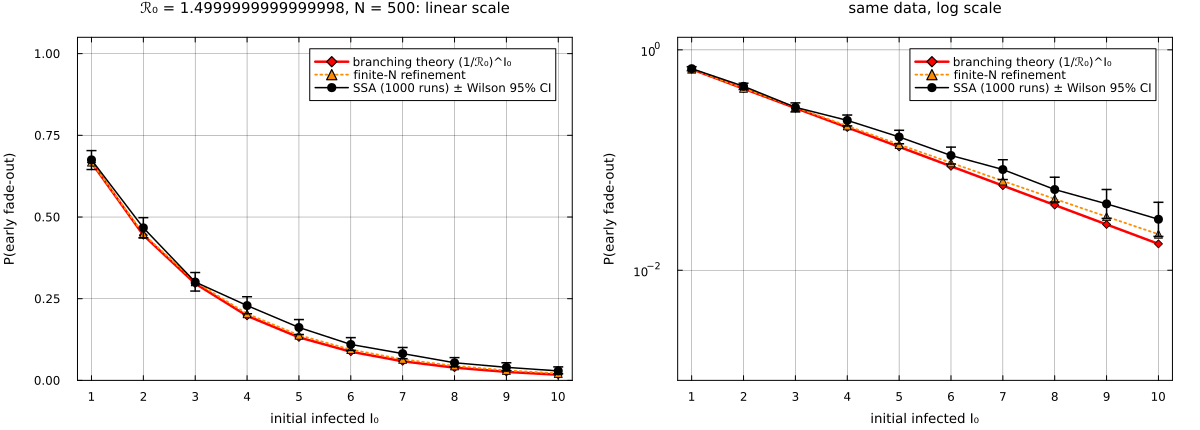

In [ ]:
floor_y = 1e-3
function sweep_plot(; logy = false)
    kw = logy ? (yscale = :log10, ylims = (floor_y, 1.3)) : (ylims = (0, 1.05),)
    pl = plot(I0_list, max.(q_th, logy ? floor_y : 0); c = :red, lw = 2.5, marker = :diamond,
              label = "branching theory (1/ℛ₀)^I₀", xlabel = "initial infected I₀",
              ylabel = "P(early fade-out)", legend = :topright, xticks = I0_list, kw...)
    plot!(pl, I0_list, max.(q_ref, logy ? floor_y : 0); c = :darkorange, lw = 1.8, ls = :dot,
          marker = :utriangle, label = "finite-N refinement")
    plot!(pl, I0_list, max.(emp, logy ? floor_y : 0); c = :black, lw = 1.5, marker = :circle, markersize = 5,
          yerror = (max.(emp .- lo, 0), max.(hi .- emp, 0)), label = "SSA ($nruns runs) ± Wilson 95% CI")
    return pl
end
pK1 = sweep_plot(logy = false); title!(pK1, "ℛ₀ = $R0_4, N = $N4: linear scale")
pK2 = sweep_plot(logy = true);  title!(pK2, "same data, log scale")
fig_kr4 = plot(pK1, pK2; layout = (1, 2), size = (1200, 430), margin = 5Plots.mm)
savefig(fig_kr4, "figures/kr4_fadeout.png")
fig_kr4

### 3. Discussion: why mean-field models miss early fade-out when $\mathcal{R}_0>1$

* **Deterministic dynamics have no extinction mechanism at small counts.** The ODE $\dot I=I(\beta S/N-\gamma)$ evolves a continuous *density*. At $t=0$ with $S\approx N$ it gives $\dot I/I=\beta-\gamma>0$, so any $I_0>0$ grows. The model says that $I_0=1$ always produces a full epidemic. It treats $1$ individual as a quantity that can be rescaled, whereas a real individual is either infectious or has recovered.
* **Demographic noise is large exactly when it matters.** The relative fluctuation of a count is $\sim1/\sqrt{I}$. At $I\sim1$–10 the random order of "infect" vs "recover" events decides the outcome. A single early recovery before the first transmission ends the outbreak. The probability that the first event is a recovery is $\gamma/(\beta+\gamma)=0.4$ for $\mathcal{R}_0=1.5$, and the full branching analysis gives $1/\mathcal{R}_0\approx0.67$ for $I_0=1$.
* **The ODE is a statement about the mean of many large populations, not about one small one.** It is accurate only as $N,I_0\to\infty$ with $I_0/N$ fixed, where extinction probability $(1/\mathcal{R}_0)^{I_0}\to0$. This is why the sweep shows extinction probability dropping geometrically with $I_0$: the ODE is the limit in which this probability vanishes.
* **The absorbing boundary.** $I=0$ is absorbing in the SSA and reachable in finite time. It is only an asymptotic fixed point of the ODE, so the mean-field model has no way to reproduce a bimodal outcome ("outbreak or nothing").
* **Observed agreement.** The empirical fractions in the table above can be compared with $(1/\mathcal{R}_0)^{I_0}$ via the Wilson intervals and z-scores. Remaining differences are expected from (i) finite $N=500$ (susceptible depletion lowers the effective $\mathcal{R}_0$, which the refined curve captures), (ii) the 10 % classification threshold rather than a true early-time criterion, and (iii) Monte Carlo error. With 1,000 runs, large-$I_0$ points rest on only about 20 or fewer fade-out events.